In [1]:

import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import random
import time
import copy
import pandas as pd

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


In [2]:

from torchvision.datasets import OxfordIIITPet

dataset = OxfordIIITPet(
    root="/content/pet_data",
    split="trainval",
    target_types="category",
    download=True
)

print("Total images:", len(dataset))
print("Total classes:", len(dataset.classes))
print("\nAvailable breeds:")

for i, breed in enumerate(dataset.classes):
    print(i, breed)


100%|██████████| 792M/792M [00:35<00:00, 22.1MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 11.7MB/s]


Total images: 3680
Total classes: 37

Available breeds:
0 Abyssinian
1 American Bulldog
2 American Pit Bull Terrier
3 Basset Hound
4 Beagle
5 Bengal
6 Birman
7 Bombay
8 Boxer
9 British Shorthair
10 Chihuahua
11 Egyptian Mau
12 English Cocker Spaniel
13 English Setter
14 German Shorthaired
15 Great Pyrenees
16 Havanese
17 Japanese Chin
18 Keeshond
19 Leonberger
20 Maine Coon
21 Miniature Pinscher
22 Newfoundland
23 Persian
24 Pomeranian
25 Pug
26 Ragdoll
27 Russian Blue
28 Saint Bernard
29 Samoyed
30 Scottish Terrier
31 Shiba Inu
32 Siamese
33 Sphynx
34 Staffordshire Bull Terrier
35 Wheaten Terrier
36 Yorkshire Terrier


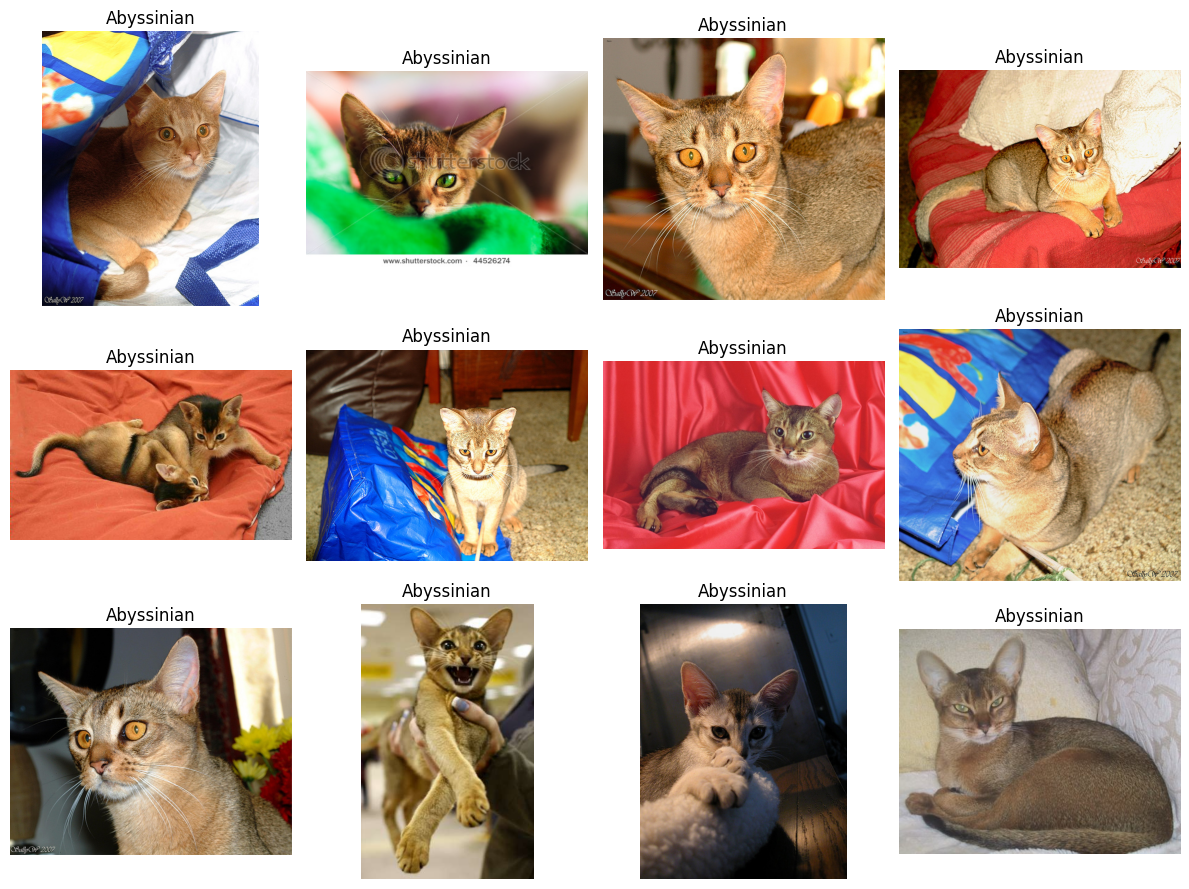

In [3]:

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    image, label = dataset[i]
    ax.imshow(image)
    ax.set_title(dataset.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


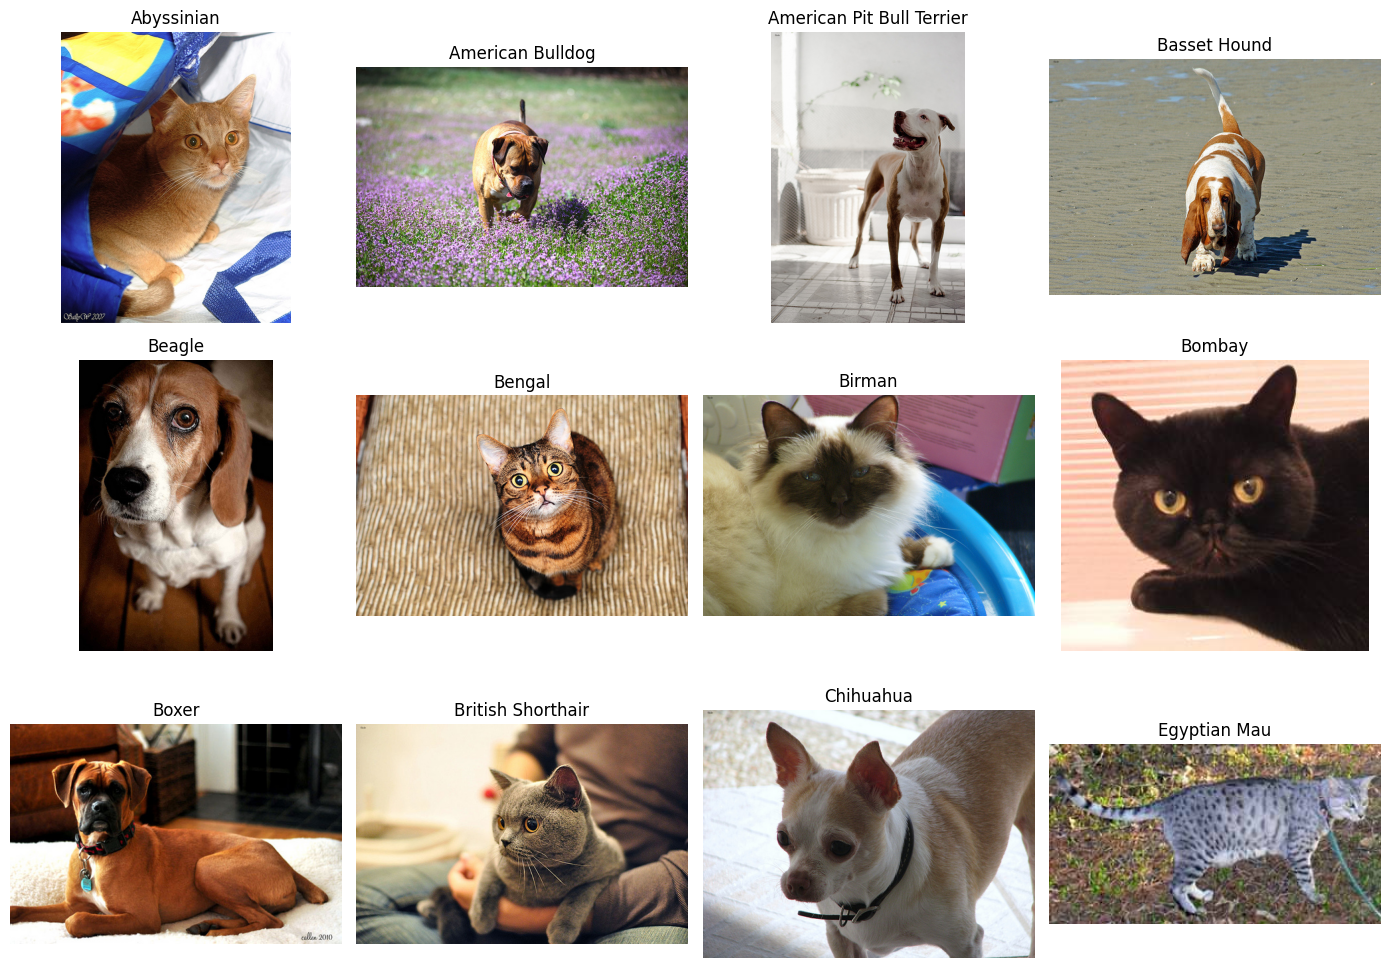

In [4]:

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

shown_breeds = set()
count = 0

for image, label in dataset:
    breed = dataset.classes[label]

    if breed not in shown_breeds:
        ax = axes.flat[count]
        ax.imshow(image)
        ax.set_title(breed)
        ax.axis("off")

        shown_breeds.add(breed)
        count += 1

    if count == 12:
        break

plt.tight_layout()
plt.show()


In [5]:

# Choose five breeds for our first experiment
selected_breeds = [
    "Abyssinian",
    "Bengal",
    "Persian",
    "Pug",
    "Siamese"
]

# Map each breed to its original dataset label
class_to_idx = {
    breed: dataset.classes.index(breed)
    for breed in selected_breeds
}

print("Selected breeds:")
for breed, label in class_to_idx.items():
    print(f"{breed}: {label}")


Selected breeds:
Abyssinian: 0
Bengal: 5
Persian: 23
Pug: 25
Siamese: 32


In [6]:

# Keep only our selected breeds and assign labels from 0 to 4
selected_data = []

for i in range(len(dataset)):
    image, label = dataset[i]

    if label in class_to_idx.values():
        new_label = selected_breeds.index(dataset.classes[label])
        selected_data.append((image, new_label))

print("Total selected images:", len(selected_data))
print("Classes:", selected_breeds)
print("New labels:", sorted(set(label for _, label in selected_data)))


Total selected images: 499
Classes: ['Abyssinian', 'Bengal', 'Persian', 'Pug', 'Siamese']
New labels: [0, 1, 2, 3, 4]


In [7]:

from collections import Counter

# Count images belonging to each class
label_counts = Counter(label for _, label in selected_data)

for label, count in sorted(label_counts.items()):
    print(f"{selected_breeds[label]}: {count} images")

print("Total:", sum(label_counts.values()))


Abyssinian: 100 images
Bengal: 100 images
Persian: 100 images
Pug: 100 images
Siamese: 99 images
Total: 499


In [8]:

# Combine the official splits before creating our experiment split
trainval_data = OxfordIIITPet(
    root="/content/pet_data",
    split="trainval",
    target_types="category",
    download=True
)

test_data = OxfordIIITPet(
    root="/content/pet_data",
    split="test",
    target_types="category",
    download=True
)

all_selected_data = []

for source_dataset in [trainval_data, test_data]:
    for image, label in source_dataset:
        if trainval_data.classes[label] in selected_breeds:
            new_label = selected_breeds.index(
                trainval_data.classes[label]
            )
            all_selected_data.append((image, new_label))

# Create a new fixed, stratified 70/15/15 split
labels = np.array([label for _, label in all_selected_data])
indices = np.arange(len(all_selected_data))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_idx]
)

# Update the dataset variable used by later cells
selected_data = all_selected_data

print("Total selected images:", len(selected_data))
print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Test images:", len(test_idx))

print("\nTraining images per class:")
for class_id, breed in enumerate(selected_breeds):
    count = np.sum(labels[train_idx] == class_id)
    print(f"{breed}: {count}")



Total selected images: 997
Training images: 697
Validation images: 150
Test images: 150

Training images per class:
Abyssinian: 138
Bengal: 140
Persian: 140
Pug: 140
Siamese: 139


In [9]:

from torchvision import transforms
from torch.utils.data import Dataset

# Use ImageNet normalization for the pretrained ResNet18
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class PetDataset(Dataset):
    def __init__(self, data, indices, transform):
        self.data = data
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, label = self.data[self.indices[index]]
        image = self.transform(image)
        return image, label

train_dataset = PetDataset(selected_data, train_idx, image_transform)
val_dataset = PetDataset(selected_data, val_idx, image_transform)
test_dataset = PetDataset(selected_data, test_idx, image_transform)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

image, label = train_dataset[0]
print("Image tensor shape:", image.shape)
print("Label:", label)
print("Breed:", selected_breeds[label])


Train dataset: 697
Validation dataset: 150
Test dataset: 150
Image tensor shape: torch.Size([3, 224, 224])
Label: 3
Breed: Pug


In [10]:

from torch.utils.data import DataLoader

BATCH_SIZE = 16

# Shuffle training images, but keep evaluation order fixed
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

# Inspect one batch
images, labels_batch = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels_batch.shape)
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))


Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])
Number of training batches: 44
Number of validation batches: 10
Number of test batches: 10


In [11]:

import torch.nn as nn

class ScratchCNN(nn.Module):
    def __init__(self, num_classes=5):
        super(ScratchCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 14 * 14, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = ScratchCNN(num_classes=len(selected_breeds)).to(device)

print("Model: CNN trained from scratch")
print("Number of output classes:", len(selected_breeds))
print("Device:", device)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))


Model: CNN trained from scratch
Number of output classes: 5
Device: cuda
Trainable parameters: 26081605


In [12]:

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Training: All CNN parameters")


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Training: All CNN parameters


In [13]:

EPOCHS = 10
best_val_loss = float("inf")
best_model_weights = copy.deepcopy(model.state_dict())
history = []

for epoch in range(EPOCHS):
    start_time = time.time()

    # Train all CNN layers
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels_batch in train_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels_batch).sum().item()
        train_total += labels_batch.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # Validate without updating weights
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels_batch in val_loader:
            images = images.to(device)
            labels_batch = labels_batch.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels_batch)

            val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels_batch).sum().item()
            val_total += labels_batch.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(model.state_dict())

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.3f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.3f} | "
        f"Time: {elapsed:.1f}s"
    )

model.load_state_dict(best_model_weights)

print("\nTraining complete.")
print("Best validation loss:", round(best_val_loss, 4))


Epoch 1/10 | Train Loss: 1.6208 | Train Acc: 0.241 | Val Loss: 1.5713 | Val Acc: 0.233 | Time: 6.5s
Epoch 2/10 | Train Loss: 1.5150 | Train Acc: 0.314 | Val Loss: 1.3531 | Val Acc: 0.493 | Time: 4.2s
Epoch 3/10 | Train Loss: 1.2629 | Train Acc: 0.475 | Val Loss: 1.2181 | Val Acc: 0.480 | Time: 3.7s
Epoch 4/10 | Train Loss: 1.0868 | Train Acc: 0.587 | Val Loss: 1.2737 | Val Acc: 0.547 | Time: 3.7s
Epoch 5/10 | Train Loss: 0.8719 | Train Acc: 0.661 | Val Loss: 1.0068 | Val Acc: 0.613 | Time: 4.2s
Epoch 6/10 | Train Loss: 0.6159 | Train Acc: 0.782 | Val Loss: 1.0402 | Val Acc: 0.600 | Time: 3.8s
Epoch 7/10 | Train Loss: 0.4536 | Train Acc: 0.845 | Val Loss: 1.1121 | Val Acc: 0.600 | Time: 3.7s
Epoch 8/10 | Train Loss: 0.3366 | Train Acc: 0.885 | Val Loss: 1.4287 | Val Acc: 0.620 | Time: 4.0s
Epoch 9/10 | Train Loss: 0.2007 | Train Acc: 0.930 | Val Loss: 1.4351 | Val Acc: 0.593 | Time: 4.1s
Epoch 10/10 | Train Loss: 0.1052 | Train Acc: 0.958 | Val Loss: 1.8769 | Val Acc: 0.573 | Time: 3.7s

In [14]:

# Evaluate the best saved model on unseen test images
model.eval()
all_predictions = []
all_labels = []
test_loss = 0.0

start_time = time.time()

with torch.no_grad():
    for images, labels_batch in test_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels_batch)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels_batch.cpu().numpy())

test_loss /= len(test_dataset)

test_accuracy = accuracy_score(all_labels, all_predictions)
test_f1 = f1_score(all_labels, all_predictions, average="macro")
test_time = time.time() - start_time

print("Test Accuracy:", round(test_accuracy, 4))
print("Macro F1 Score:", round(test_f1, 4))
print("Test Loss:", round(test_loss, 4))
print("Evaluation Time:", round(test_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(selected_breeds))),
    target_names=selected_breeds,
    zero_division=0
))


Test Accuracy: 0.5533
Macro F1 Score: 0.5501
Test Loss: 1.1306
Evaluation Time: 0.48 seconds

Classification Report:
              precision    recall  f1-score   support

  Abyssinian       0.44      0.63      0.52        30
      Bengal       0.76      0.53      0.63        30
     Persian       0.65      0.37      0.47        30
         Pug       0.72      0.43      0.54        30
     Siamese       0.47      0.80      0.59        30

    accuracy                           0.55       150
   macro avg       0.61      0.55      0.55       150
weighted avg       0.61      0.55      0.55       150



In [15]:


# Rows = actual breeds, columns = predicted breeds
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(selected_breeds)))
)

cm_df = pd.DataFrame(
    cm,
    index=selected_breeds,
    columns=selected_breeds
)

print("Confusion Matrix:")
print(cm_df)



Confusion Matrix:
            Abyssinian  Bengal  Persian  Pug  Siamese
Abyssinian          19       2        3    0        6
Bengal               6      16        0    2        6
Persian             13       1       11    0        5
Pug                  3       1        3   13       10
Siamese              2       1        0    3       24


In [16]:

# Display the training and validation results for each epoch
history_df = pd.DataFrame(history)

print(history_df.round(4).to_string(index=False))


 epoch  train_loss  train_accuracy  val_loss  val_accuracy
     1      1.6208          0.2410    1.5713        0.2333
     2      1.5150          0.3142    1.3531        0.4933
     3      1.2629          0.4749    1.2181        0.4800
     4      1.0868          0.5868    1.2737        0.5467
     5      0.8719          0.6614    1.0068        0.6133
     6      0.6159          0.7819    1.0402        0.6000
     7      0.4536          0.8451    1.1121        0.6000
     8      0.3366          0.8852    1.4287        0.6200
     9      0.2007          0.9297    1.4351        0.5933
    10      0.1052          0.9584    1.8769        0.5733


In [17]:

# Create fixed, balanced subsets from the training split
shots_per_class = [5, 10, 25, 50, 100]
few_shot_indices = {}

train_labels = np.array([
    selected_data[i][1] for i in train_idx
])

rng = np.random.default_rng(SEED)

for shots in shots_per_class:
    chosen_indices = []

    for class_id in range(len(selected_breeds)):
        class_indices = train_idx[train_labels == class_id]
        selected = rng.choice(
            class_indices,
            size=shots,
            replace=False
        )
        chosen_indices.extend(selected.tolist())

    few_shot_indices[shots] = chosen_indices

    print(
        f"{shots} images/class: "
        f"{len(chosen_indices)} total images"
    )


5 images/class: 25 total images
10 images/class: 50 total images
25 images/class: 125 total images
50 images/class: 250 total images
100 images/class: 500 total images


In [18]:

shots_results = []
few_shot_predictions = {}
few_shot_actual = {}

for shots in [5, 10, 25, 50, 100]:
    print(f"\nTraining with {shots} images per class...")

    start_time = time.time()

    torch.manual_seed(SEED + shots)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED + shots)

    few_dataset = PetDataset(
        selected_data,
        few_shot_indices[shots],
        image_transform
    )

    few_loader = DataLoader(
        few_dataset,
        batch_size=16,
        shuffle=True
    )

    # Create a new CNN with randomly initialized weights
    few_model = ScratchCNN(
        num_classes=len(selected_breeds)
    ).to(device)

    few_optimizer = optim.Adam(
        few_model.parameters(),
        lr=0.001
    )

    best_loss = float("inf")
    best_weights = copy.deepcopy(few_model.state_dict())

    for epoch in range(10):
        # Train all CNN layers
        few_model.train()

        for images, labels_batch in few_loader:
            images = images.to(device)
            labels_batch = labels_batch.to(device)

            few_optimizer.zero_grad()

            outputs = few_model(images)
            loss = criterion(outputs, labels_batch)

            loss.backward()
            few_optimizer.step()

        # Validate and select the best checkpoint
        few_model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for images, labels_batch in val_loader:
                images = images.to(device)
                labels_batch = labels_batch.to(device)

                outputs = few_model(images)
                loss = criterion(outputs, labels_batch)

                val_loss += loss.item() * images.size(0)

        val_loss /= len(val_dataset)

        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = copy.deepcopy(few_model.state_dict())

    few_model.load_state_dict(best_weights)
    few_model.eval()

    predictions = []
    actual = []

    with torch.no_grad():
        for images, labels_batch in test_loader:
            images = images.to(device)
            labels_batch = labels_batch.to(device)

            outputs = few_model(images)

            predictions.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )
            actual.extend(labels_batch.cpu().numpy())

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    experiment_time = time.time() - start_time

    few_shot_predictions[shots] = predictions
    few_shot_actual[shots] = actual

    accuracy = accuracy_score(actual, predictions)

    macro_f1 = f1_score(
        actual,
        predictions,
        labels=list(range(len(selected_breeds))),
        average="macro",
        zero_division=0
    )

    shots_results.append({
        "Images per class": shots,
        "Total training images": len(few_dataset),
        "Best validation loss": round(best_loss, 4),
        "Test accuracy": round(accuracy, 4),
        "Macro F1": round(macro_f1, 4),
        "Experiment Time (seconds)": round(experiment_time, 2)
    })

    print(f"Test accuracy: {accuracy:.2%}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Experiment time: {experiment_time:.2f} seconds")

print("\nFew-shot experiment results:")
print(pd.DataFrame(shots_results).to_string(index=False))



Training with 5 images per class...
Test accuracy: 22.00%
Macro F1: 0.2162
Experiment time: 7.38 seconds

Training with 10 images per class...
Test accuracy: 24.00%
Macro F1: 0.1883
Experiment time: 6.78 seconds

Training with 25 images per class...
Test accuracy: 36.00%
Macro F1: 0.3351
Experiment time: 9.26 seconds

Training with 50 images per class...
Test accuracy: 39.33%
Macro F1: 0.3680
Experiment time: 12.53 seconds

Training with 100 images per class...
Test accuracy: 43.33%
Macro F1: 0.4355
Experiment time: 20.19 seconds

Few-shot experiment results:
 Images per class  Total training images  Best validation loss  Test accuracy  Macro F1  Experiment Time (seconds)
                5                     25                1.5889         0.2200    0.2162                       7.38
               10                     50                1.5983         0.2400    0.1883                       6.78
               25                    125                1.3002         0.3600    0.3351 

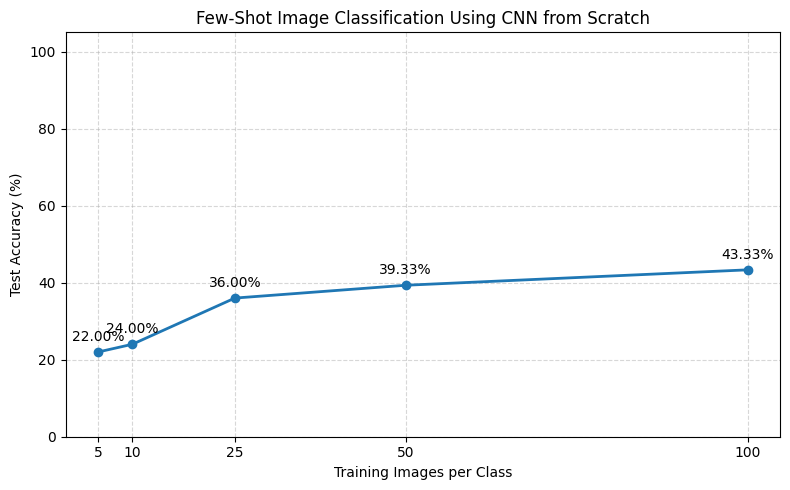

In [20]:

# Plot how test accuracy changes with the amount of training data
results_df = pd.DataFrame(shots_results)

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Images per class"],
    results_df["Test accuracy"] * 100,
    marker="o",
    linewidth=2
)

plt.xlabel("Training Images per Class")
plt.ylabel("Test Accuracy (%)")
plt.title("Few-Shot Image Classification Using CNN from Scratch")
plt.xticks([5, 10, 25, 50, 100])
plt.ylim(0, 105)
plt.grid(True, linestyle="--", alpha=0.5)

for _, row in results_df.iterrows():
    plt.annotate(
        f'{row["Test accuracy"] * 100:.2f}%',
        (row["Images per class"], row["Test accuracy"] * 100),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.tight_layout()
plt.show()



In [21]:

# Print precision, recall, and F1-score for each experiment
for shots in [5, 10, 25, 50, 100]:
    print(f"\n{'=' * 45}")
    print(f"Classification Report: {shots} Images per Class")
    print("=" * 45)

    print(classification_report(
        few_shot_actual[shots],
        few_shot_predictions[shots],
        labels=list(range(len(selected_breeds))),
        target_names=selected_breeds,
        zero_division=0
    ))



Classification Report: 5 Images per Class
              precision    recall  f1-score   support

  Abyssinian       0.19      0.20      0.19        30
      Bengal       0.18      0.30      0.23        30
     Persian       0.21      0.30      0.25        30
         Pug       0.25      0.10      0.14        30
     Siamese       0.40      0.20      0.27        30

    accuracy                           0.22       150
   macro avg       0.25      0.22      0.22       150
weighted avg       0.25      0.22      0.22       150


Classification Report: 10 Images per Class
              precision    recall  f1-score   support

  Abyssinian       0.21      0.37      0.27        30
      Bengal       1.00      0.07      0.12        30
     Persian       0.36      0.17      0.23        30
         Pug       0.00      0.00      0.00        30
     Siamese       0.22      0.60      0.32        30

    accuracy                           0.24       150
   macro avg       0.36      0.24      0.19 

In [22]:

# Summarize macro metrics for each few-shot experiment
report_rows = []

for shots in [5, 10, 25, 50, 100]:
    report = classification_report(
        few_shot_actual[shots],
        few_shot_predictions[shots],
        labels=list(range(len(selected_breeds))),
        target_names=selected_breeds,
        output_dict=True,
        zero_division=0
    )

    report_rows.append({
        "Images per class": shots,
        "Macro Precision": round(report["macro avg"]["precision"], 4),
        "Macro Recall": round(report["macro avg"]["recall"], 4),
        "Macro F1": round(report["macro avg"]["f1-score"], 4)
    })

metrics_df = pd.DataFrame(report_rows)
print(metrics_df.to_string(index=False))


 Images per class  Macro Precision  Macro Recall  Macro F1
                5           0.2471        0.2200    0.2162
               10           0.3574        0.2400    0.1883
               25           0.3526        0.3600    0.3351
               50           0.3755        0.3933    0.3680
              100           0.4485        0.4333    0.4355


In [23]:

# Combine the experiment metrics into one report table
final_results = pd.DataFrame(shots_results).merge(
    metrics_df,
    on="Images per class"
)

final_results.to_csv(
    "few_shot_experiment_results.csv",
    index=False
)

print("Results saved successfully!")
print(final_results.to_string(index=False))


Results saved successfully!
 Images per class  Total training images  Best validation loss  Test accuracy  Macro F1_x  Experiment Time (seconds)  Macro Precision  Macro Recall  Macro F1_y
                5                     25                1.5889         0.2200      0.2162                       7.38           0.2471        0.2200      0.2162
               10                     50                1.5983         0.2400      0.1883                       6.78           0.3574        0.2400      0.1883
               25                    125                1.3002         0.3600      0.3351                       9.26           0.3526        0.3600      0.3351
               50                    250                1.4278         0.3933      0.3680                      12.53           0.3755        0.3933      0.3680
              100                    500                1.2164         0.4333      0.4355                      20.19           0.4485        0.4333      0.4355


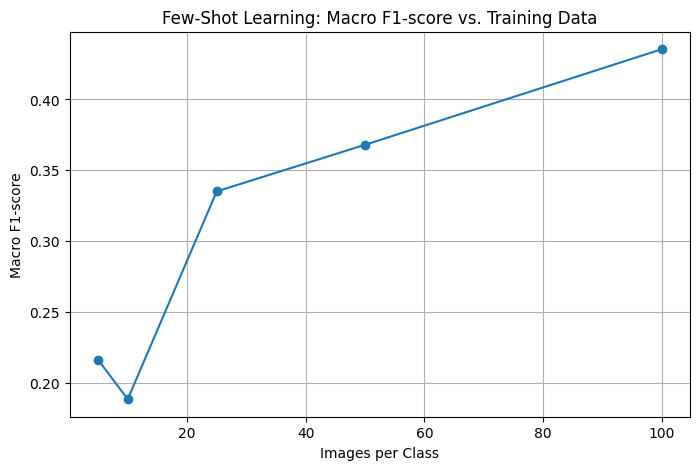

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    metrics_df["Images per class"],
    metrics_df["Macro F1"],
    marker="o"
)

plt.xlabel("Images per Class")
plt.ylabel("Macro F1-score")
plt.title("Few-Shot Learning: Macro F1-score vs. Training Data")
plt.grid(True)
plt.show()

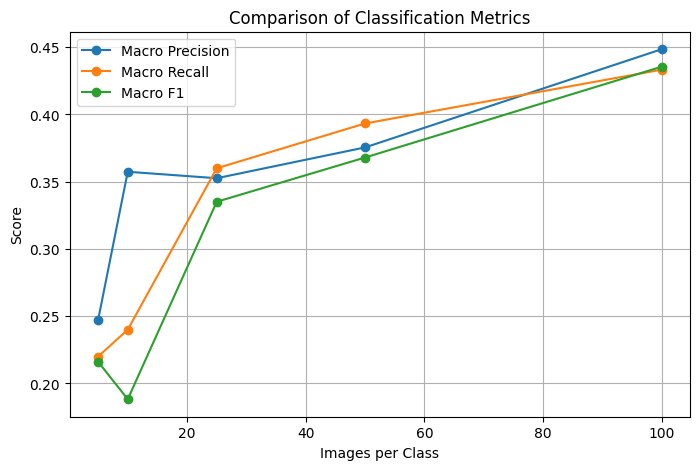

In [25]:
plt.figure(figsize=(8, 5))

for metric in ["Macro Precision", "Macro Recall", "Macro F1"]:
    plt.plot(
        metrics_df["Images per class"],
        metrics_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Images per Class")
plt.ylabel("Score")
plt.title("Comparison of Classification Metrics")
plt.legend()
plt.grid(True)
plt.show()

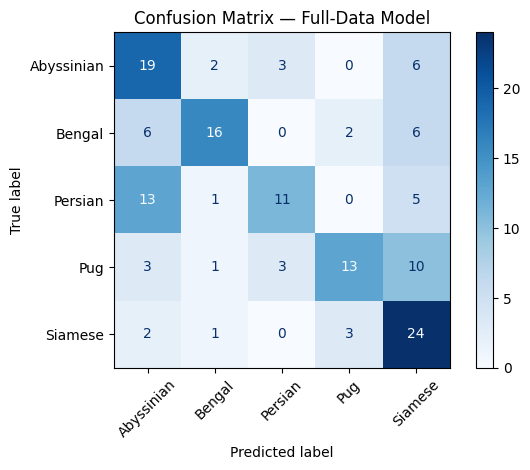

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(selected_breeds)))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=selected_breeds
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Confusion Matrix — Full-Data Model")
plt.tight_layout()
plt.show()

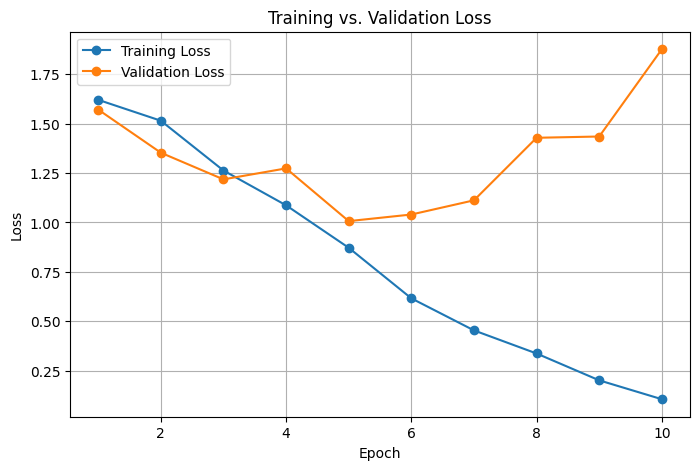

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training Loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs. Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

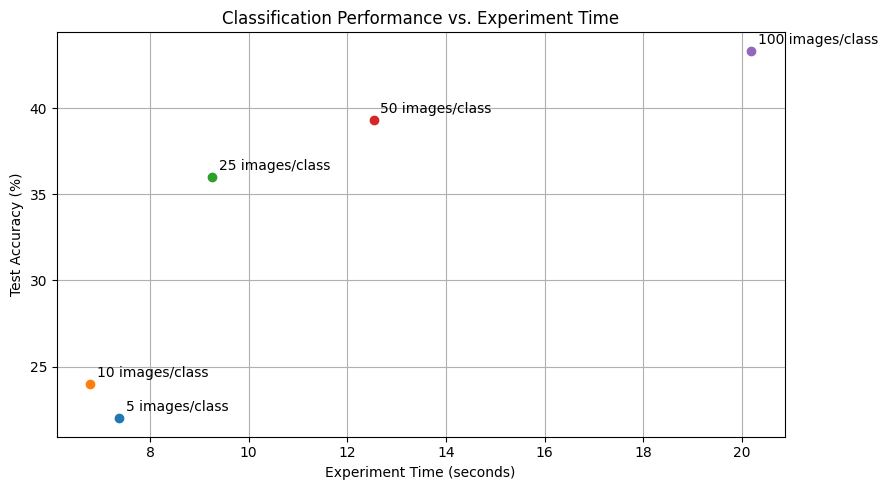

In [28]:

plt.figure(figsize=(9, 5))

for result in shots_results:
    plt.scatter(
        result["Experiment Time (seconds)"],
        result["Test accuracy"] * 100
    )

    plt.annotate(
        f'{result["Images per class"]} images/class',
        (
            result["Experiment Time (seconds)"],
            result["Test accuracy"] * 100
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Experiment Time (seconds)")
plt.ylabel("Test Accuracy (%)")
plt.title("Classification Performance vs. Experiment Time")
plt.grid(True)
plt.tight_layout()
plt.show()


In [30]:

import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = len(selected_breeds)
EPOCHS = 10
LEARNING_RATE = 0.001

start_time = time.time()

# Initialize CNN from scratch
model = ScratchCNN(num_classes=NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

best_val_loss = float("inf")
best_weights = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    model.eval()
    val_loss = 0.0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_total += labels.size(0)

    val_loss /= val_total

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

# Restore the best checkpoint
model.load_state_dict(best_weights)
torch.save(model.state_dict(), "scratch_cnn_full_dataset.pth")

# Evaluate on the test set
model.eval()
all_predictions = []
all_labels = []
test_loss = 0.0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        test_total += labels.size(0)

        predictions = outputs.argmax(dim=1)
        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

test_loss /= test_total

test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

experiment_time = time.time() - start_time

print("\n===== FULL-DATASET CNN FROM SCRATCH RESULTS =====")
print(f"Training images: {len(train_loader.dataset)}")
print(f"Validation images: {len(val_loader.dataset)}")
print(f"Test images: {len(test_loader.dataset)}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro precision: {test_precision:.4f}")
print(f"Macro recall: {test_recall:.4f}")
print(f"Macro F1-score: {test_f1:.4f}")
print(f"Total experiment time: {experiment_time:.2f} seconds")
print("Best model saved as scratch_cnn_full_dataset.pth")

Epoch [1/10] Train Loss: 1.6378 | Train Accuracy: 0.2267 | Val Loss: 1.5380
Epoch [2/10] Train Loss: 1.4887 | Train Accuracy: 0.3386 | Val Loss: 1.4895
Epoch [3/10] Train Loss: 1.3661 | Train Accuracy: 0.4075 | Val Loss: 1.3910
Epoch [4/10] Train Loss: 1.2833 | Train Accuracy: 0.4462 | Val Loss: 1.3053
Epoch [5/10] Train Loss: 1.2346 | Train Accuracy: 0.4763 | Val Loss: 1.3626
Epoch [6/10] Train Loss: 1.1393 | Train Accuracy: 0.5323 | Val Loss: 1.2650
Epoch [7/10] Train Loss: 1.0020 | Train Accuracy: 0.5911 | Val Loss: 1.2078
Epoch [8/10] Train Loss: 0.8779 | Train Accuracy: 0.6528 | Val Loss: 1.1958
Epoch [9/10] Train Loss: 0.7256 | Train Accuracy: 0.7088 | Val Loss: 1.2066
Epoch [10/10] Train Loss: 0.5664 | Train Accuracy: 0.7848 | Val Loss: 1.3832

===== FULL-DATASET CNN FROM SCRATCH RESULTS =====
Training images: 697
Validation images: 150
Test images: 150
Best validation loss: 1.1958
Test loss: 1.1157
Test accuracy: 62.67%
Macro precision: 0.6380
Macro recall: 0.6267
Macro F1-scor